<a href="https://colab.research.google.com/github/asmipandey18/Elevvo_Ml_Internship/blob/main/Student_score_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task 1 : Student Score Prediction


In [3]:
## import libraries
import pandas as pd

In [4]:
df = pd.read_csv("/content/StudentPerformanceFactors.csv")

In [5]:
df.head(10)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


In [6]:
df.shape

(6607, 20)

## Data cleaning

In [7]:
# 1. Check dataset information
print("Dataset Information:")
df.info()

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# 5. Remove duplicate rows
df = df.drop_duplicates()

# 6. Display final dataset shape
print("\nDataset shape after removing duplicates:", df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence             

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
count,6607.000000,6607.000000,6607,6607,6607,6607.00000,6607.000000,6607,6607,6607.000000,6607,6529,6607,6607,6607.000000,6607,6517,6540,6607,6607.000000
unique,NaN,NaN,3,3,2,NaN,NaN,3,2,NaN,3,3,2,3,NaN,2,3,3,2,NaN
top,NaN,NaN,Medium,Medium,Yes,NaN,NaN,Medium,Yes,NaN,Low,Medium,Public,Positive,NaN,No,High School,Near,Male,NaN
freq,NaN,NaN,3362,3319,3938,NaN,NaN,3351,6108,NaN,2672,3925,4598,2638,NaN,5912,3223,3884,3814,NaN
mean,19.975329,79.977448,NaN,NaN,NaN,7.02906,75.070531,NaN,NaN,1.493719,NaN,NaN,NaN,NaN,2.967610,NaN,NaN,NaN,NaN,67.235659
std,5.990594,11.547475,NaN,NaN,NaN,1.46812,14.399784,NaN,NaN,1.230570,NaN,NaN,NaN,NaN,1.031231,NaN,NaN,NaN,NaN,3.890456
min,1.000000,60.000000,NaN,NaN,NaN,4.00000,50.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,55.000000
25%,16.000000,70.000000,NaN,NaN,NaN,6.00000,63.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,65.000000
50%,20.000000,80.000000,NaN,NaN,NaN,7.00000,75.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,67.000000
75%,24.000000,90.000000,NaN,NaN,NaN,8.00000,88.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,69.000000



Dataset shape after removing duplicates: (6607, 20)


In [8]:
# Fill missing values using the most frequent category
columns_to_fill = [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]

for col in columns_to_fill:
    df[col] = df[col].fillna(df[col].mode()[0])

# Verify the cleaning
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Total missing values: 0
Duplicate rows: 0
Dataset shape: (6607, 20)


## Data Visualization

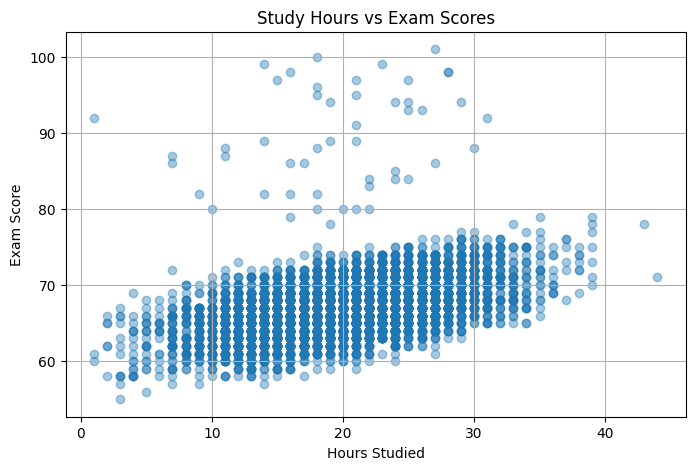

In [9]:
## 1. Study Hours vs Exam Scores
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    alpha=0.4
)

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.grid(True)

plt.show()

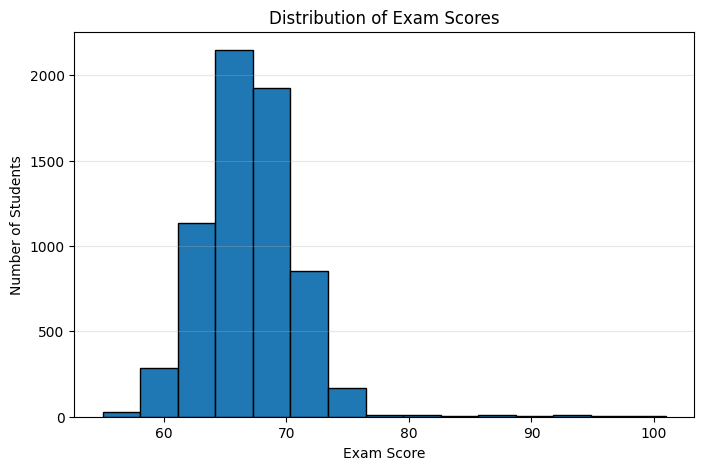

In [10]:
## 2. Exam Score Distribution
plt.figure(figsize=(8, 5))

plt.hist(df["Exam_Score"], bins=15, edgecolor="black")

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)

plt.show()

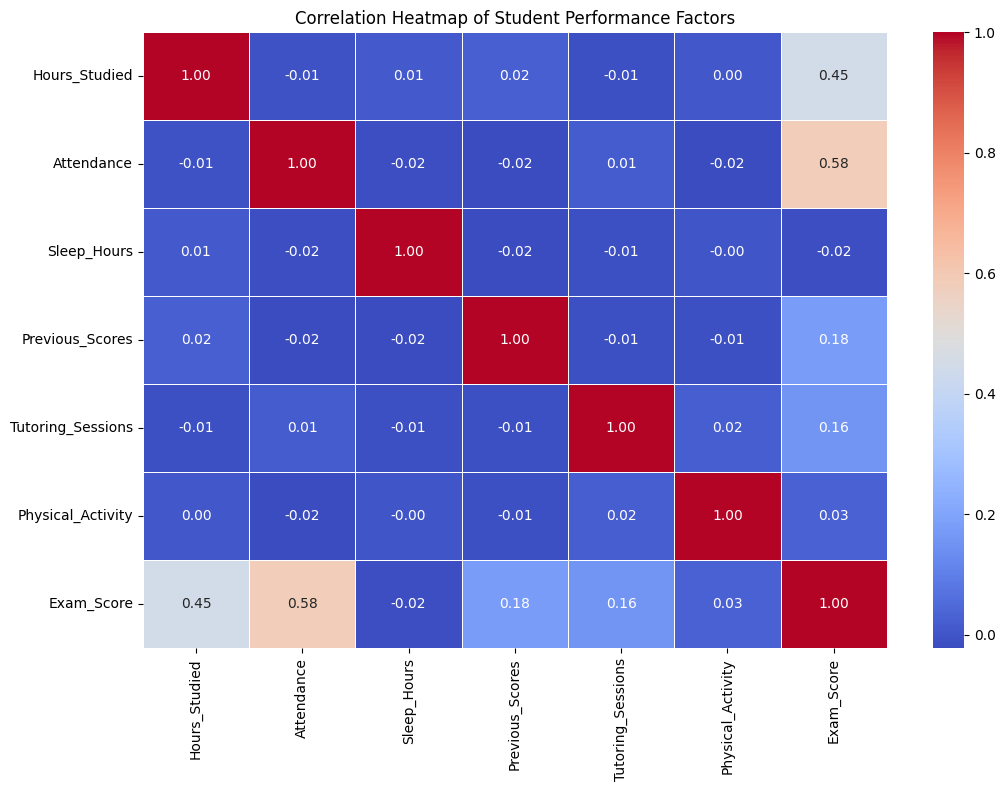

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns only
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance Factors")
plt.show()

In [12]:
## Separate input and output
# Input feature: hours studied
X = df[["Hours_Studied"]]

# Target variable: exam score
y = df["Exam_Score"]

# Check the data
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print(X.head())
print(y.head())

Input shape: (6607, 1)
Target shape: (6607,)
   Hours_Studied
0             23
1             19
2             24
3             29
4             19
0    67
1    61
2    74
3    71
4    70
Name: Exam_Score, dtype: int64


## Split the dataset

In [13]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

## Train the model


In [28]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)


LinearRegression()

In [15]:
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 0.285668744443087
Intercept: 61.51116746904424


In [16]:
# Predict exam scores using the test data
y_pred = model.predict(X_test)

# Display actual and predicted scores
print("Actual exam scores:")
print(y_test.head(10).to_list())

print("\nPredicted exam scores:")
print(y_pred[:10].round(2))

Actual exam scores:
[65, 65, 71, 64, 66, 66, 72, 66, 70, 70]

Predicted exam scores:
[67.22 67.8  67.51 64.94 67.51 67.51 72.08 68.37 66.37 66.08]


## Evaluate model performance

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("-------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

Model Evaluation Results
-------------------------
MAE: 2.45
MSE: 10.86
RMSE: 3.29
R² Score: 0.232


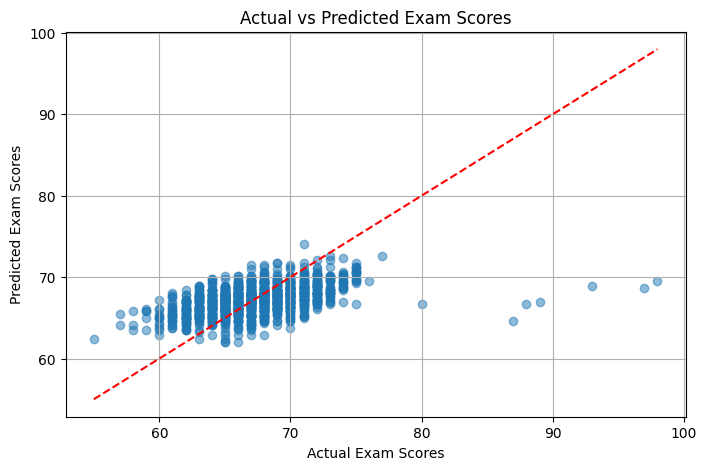

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Actual vs Predicted Exam Scores")
plt.grid(True)
plt.show()

## Bonus
Create the Polynomial Regression model

In [19]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

In [27]:
# Create Polynomial Regression model with degree 2
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train the model using the same training data
poly_model.fit(X_train, y_train)


Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(include_bias=False)),
                ('linearregression', LinearRegression())])

In [21]:

# Predict exam scores using Polynomial Regression
y_poly_pred = poly_model.predict(X_test)

# Calculate evaluation metrics
poly_mae = mean_absolute_error(y_test, y_poly_pred)
poly_mse = mean_squared_error(y_test, y_poly_pred)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, y_poly_pred)

# Display results
print("Polynomial Regression Results")
print("------------------------------")
print("MAE:", round(poly_mae, 2))
print("MSE:", round(poly_mse, 2))
print("RMSE:", round(poly_rmse, 2))
print("R² Score:", round(poly_r2, 4))


Polynomial Regression Results
------------------------------
MAE: 2.44
MSE: 10.84
RMSE: 3.29
R² Score: 0.2328


## Compare Linear Regression vs Ploynomial Regression

In [23]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Linear Regression": [
        mae,
        mse,
        rmse,
        r2
    ],
    "Polynomial Regression": [
        poly_mae,
        poly_mse,
        poly_rmse,
        poly_r2
    ]
})

print(comparison.round(4).to_string(index=False))


  Metric  Linear Regression  Polynomial Regression
     MAE             2.4476                 2.4448
     MSE            10.8559                10.8450
    RMSE             3.2948                 3.2932
R² Score             0.2320                 0.2328


## Feature Combination Experiment

In [24]:
# Select multiple numerical features
X_multi = df[
    [
        "Hours_Studied",
        "Attendance",
        "Sleep_Hours",
        "Previous_Scores",
        "Tutoring_Sessions",
        "Physical_Activity"
    ]
]

# Target variable
y = df["Exam_Score"]


In [26]:
X_multi_train, X_multi_test, y_multi_train, y_multi_test = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

# Train the multiple-feature Linear Regression model
multi_model = LinearRegression()
multi_model.fit(X_multi_train, y_multi_train)


LinearRegression()

In [29]:
# Make predictions
y_multi_pred = multi_model.predict(X_multi_test)

In [30]:
# Evaluate the model
multi_mae = mean_absolute_error(y_multi_test, y_multi_pred)
multi_mse = mean_squared_error(y_multi_test, y_multi_pred)
multi_rmse = np.sqrt(multi_mse)
multi_r2 = r2_score(y_multi_test, y_multi_pred)

print("Multiple-Feature Linear Regression Results")
print("------------------------------------------")
print("MAE:", round(multi_mae, 4))
print("MSE:", round(multi_mse, 4))
print("RMSE:", round(multi_rmse, 4))
print("R² Score:", round(multi_r2, 4))


Multiple-Feature Linear Regression Results
------------------------------------------
MAE: 1.2659
MSE: 5.0655
RMSE: 2.2507
R² Score: 0.6416


## Compare all three model

In [31]:
comparison_all = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Linear Regression (Study Hours)": [
        mae, mse, rmse, r2
    ],
    "Polynomial Regression": [
        poly_mae, poly_mse, poly_rmse, poly_r2
    ],
    "Multiple-Feature Regression": [
        multi_mae, multi_mse, multi_rmse, multi_r2
    ]
})

print(comparison_all.round(4).to_string(index=False))

  Metric  Linear Regression (Study Hours)  Polynomial Regression  Multiple-Feature Regression
     MAE                           2.4476                 2.4448                       1.2659
     MSE                          10.8559                10.8450                       5.0655
    RMSE                           3.2948                 3.2932                       2.2507
R² Score                           0.2320                 0.2328                       0.6416


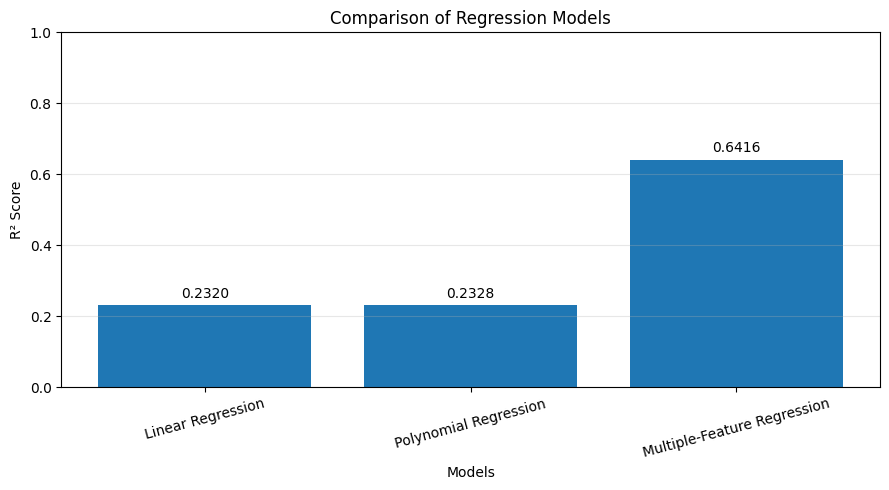

In [32]:

import matplotlib.pyplot as plt

# Model names and their R² scores
model_names = [
    "Linear Regression",
    "Polynomial Regression",
    "Multiple-Feature Regression"
]

r2_scores = [r2, poly_r2, multi_r2]

# Create bar chart
plt.figure(figsize=(9, 5))
bars = plt.bar(model_names, r2_scores)

plt.title("Comparison of Regression Models")
plt.xlabel("Models")
plt.ylabel("R² Score")
plt.ylim(0, 1)

# Display values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center"
    )

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Conclusion

In this project, I developed regression models to predict student exam scores using the Student Performance Factors dataset.

First, I cleaned the dataset by handling missing values and checking for duplicate records. I then explored the relationship between study hours and exam scores using visualizations.

I trained and evaluated three models: Linear Regression, Polynomial Regression, and Multiple-Feature Linear Regression.

The Multiple-Feature Linear Regression model performed best, achieving an **R² score of 0.6416**, an **MAE of 1.2659**, and an **RMSE of 2.2507** on the test set. This suggests that using multiple numerical features improved predictions compared with using study hours alone.

Overall, this project helped me understand data cleaning, exploratory data analysis, train-test splitting, regression modeling, model evaluation, and visualization using Python, Pandas, Matplotlib, and Scikit-learn.